# Who is left out of digital finance? Predicting account type in Sub-Saharan Africa

**Author:** Aime Igirimpuhwe | Machine Learning Summative

**Question.** Given what a survey can learn about an adult (age, education, income, phone and internet access, how they earn and save), can we predict which kind of financial account they have: none, mobile money only, a financial institution account only, or both?

**Why it matters to me.** My personal mission is to help people in Rwanda, especially small business owners, use digital tools and services, including digital finance. Knowing who is still excluded, and whether mobile money is reaching people that banks miss, is exactly the kind of evidence that should decide where digital finance products and outreach go.

**Data.** World Bank Global Findex Database 2021 microdata (143,887 adults in 139 economies, DOI 10.48529/jq97-aj70). I keep the Sub-Saharan Africa sample, where mobile money questions were asked.

**Notebook map**
1. Setup and reproducibility
2. Loading the raw data
3. Target definition and class balance
4. Leakage audit and feature selection
5. Feature engineering and preprocessing pipeline
6. Data splits
7. Experiment tracking helpers (TensorBoard)
8. Traditional ML experiments (scikit-learn)
9. Deep learning experiments (Keras Functional API + tf.data)
10. Experiment table
11. Final test evaluation of the best ML and DL models
12. Learning curves and bias-variance analysis
13. Error analysis
14. Generalisation to unseen countries
15. Saving the best models

## 1. Setup

All randomness (data split, model initialisation, shuffling, hyperparameter search) is controlled by one seed. If you run this on Colab, the first cell installs nothing extra: everything used here ships with Colab. Locally, install `requirements.txt` first.

In [1]:
import json
import os
import random
import sys
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tensorflow as tf
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, GroupKFold, RandomizedSearchCV, StratifiedKFold,
                                     learning_curve, train_test_split, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_class_weight
from tensorboard.plugins.hparams import api as hp
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("Python", sys.version.split()[0], "| TensorFlow", tf.__version__, "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__)

Python 3.13.7 | TensorFlow 2.21.0 | scikit-learn 1.9.1 | pandas 3.0.6


In [2]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/Findex_Summative"
else:
    BASE_DIR = "."

DATA_DIR = os.path.join(BASE_DIR, "data")
LOG_DIR = os.path.join(BASE_DIR, "logs", "fit")
MODEL_DIR = os.path.join(BASE_DIR, "models")
FIG_DIR = os.path.join(BASE_DIR, "figures")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
for d in (DATA_DIR, LOG_DIR, MODEL_DIR, FIG_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)


def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")

## 2. Loading the raw data

The Findex microdata needs a free World Bank Microdata Library account, so the file is not downloaded automatically and it is **not** committed to GitHub. Download `micro_world_139countries` (Stata or CSV) from https://microdata.worldbank.org/index.php/catalog/4607 and put it in `data/` (or the zipped copy from my Google Drive folder). The loader accepts `.dta`, `.csv` or a `.zip` containing either.

I load the numeric codes instead of the text labels, because the codebook defines special codes such as "don't know" and "refused" that I need to handle myself.

In [3]:
def find_raw_file(data_dir):
    names = sorted(os.listdir(data_dir))
    for name in names:
        if name.lower().startswith("micro_world") and name.lower().endswith((".dta", ".csv")):
            return os.path.join(data_dir, name)
    for name in names:
        if "findex" in name.lower() and name.lower().endswith(".zip"):
            return os.path.join(data_dir, name)
    raise FileNotFoundError(f"Put WLD_2021_FINDEX_v03_M_csv.zip (or micro_world_139countries.csv) in {data_dir}")


def load_findex(path):
    if path.endswith(".zip"):
        import zipfile
        with zipfile.ZipFile(path) as z:
            inner = [n for n in z.namelist() if n.lower().endswith((".dta", ".csv"))][0]
            z.extract(inner, DATA_DIR)
        path = os.path.join(DATA_DIR, inner)
    if path.endswith(".dta"):
        return pd.read_stata(path, convert_categoricals=False)
    return pd.read_csv(path, low_memory=False, encoding="latin-1")  # the World Bank CSV is Latin-1 encoded


RAW_PATH = find_raw_file(DATA_DIR)
raw = load_findex(RAW_PATH)
print(f"Raw file: {RAW_PATH}")
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head(3)

Raw file: ./data/WLD_2021_FINDEX_v03_M_csv.zip
Raw shape: 143,887 rows x 128 columns


,economy,economycode,regionwb,pop_adult,wpid_random,wgt,female,age,educ,inc_q,...,receive_transfers,receive_pension,receive_agriculture,pay_utilities,remittances,mobileowner,internetaccess,anydigpayment,merchantpay_dig,year
0,Afghanistan,AFG,South Asia,22647496.0,144274031,0.716416,2,43.0,2,4,...,4,4,4.0,1,5.0,1,2,1,0.0,2021
1,Afghanistan,AFG,South Asia,22647496.0,180724554,0.497408,2,55.0,1,3,...,4,4,2.0,4,5.0,1,2,0,0.0,2021
2,Afghanistan,AFG,South Asia,22647496.0,130686682,0.650431,1,15.0,1,2,...,4,4,4.0,4,3.0,2,2,0,0.0,2021


## 3. Target definition and class balance

Findex records two separate yes/no answers: `account_fin` (has an account at a bank or other financial institution) and `account_mob` (has a mobile money account). Combining them gives four classes, which is more informative than the usual "banked vs unbanked" split because it shows *how* people are included:

| Class | account_fin | account_mob |
|---|---|---|
| 0. No account | 0 | 0 |
| 1. Mobile money only | 0 | 1 |
| 2. Financial institution only | 1 | 0 |
| 3. Both | 1 | 1 |

I keep Sub-Saharan Africa because that is where the mobile money questions were asked and where my mission is focused. Rows where `account_mob` was not asked are dropped.

Sub-Saharan Africa rows: 36,062 from 36 economies
Rows with both account questions answered: 36,062


,class,rows,share
0,No account,16472,0.457
1,Mobile money only,6372,0.177
2,Financial institution only,6424,0.178
3,Both,6794,0.188


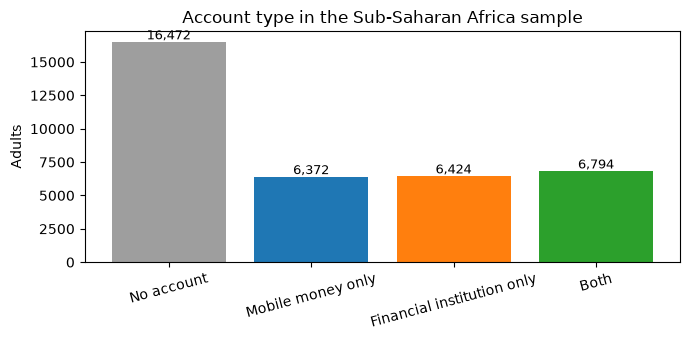

In [4]:
CLASS_NAMES = ["No account", "Mobile money only", "Financial institution only", "Both"]
SSA = "Sub-Saharan Africa (excluding high income)"

df = raw[raw["regionwb"] == SSA].copy()
print(f"Sub-Saharan Africa rows: {len(df):,} from {df['economy'].nunique()} economies")
df = df.dropna(subset=["account_fin", "account_mob"])
df["target"] = (df["account_fin"].astype(int) * 2 + df["account_mob"].astype(int)).astype(int)
print(f"Rows with both account questions answered: {len(df):,}")

counts = df["target"].value_counts().sort_index()
balance = pd.DataFrame({"class": CLASS_NAMES, "rows": counts.values, "share": (counts / counts.sum()).round(3).values})
display(balance)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(CLASS_NAMES, counts.values, color=["#9e9e9e", "#1f77b4", "#ff7f0e", "#2ca02c"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Adults")
ax.set_title("Account type in the Sub-Saharan Africa sample")
plt.xticks(rotation=15)
plt.tight_layout()
save_fig("class_balance")
plt.show()

**What this shows.** 45.7% of adults have no account, and each of the other three classes is about 18%. A model that always says "No account" would be right 45.7% of the time but useless, which is why macro F1 is my main metric rather than accuracy.

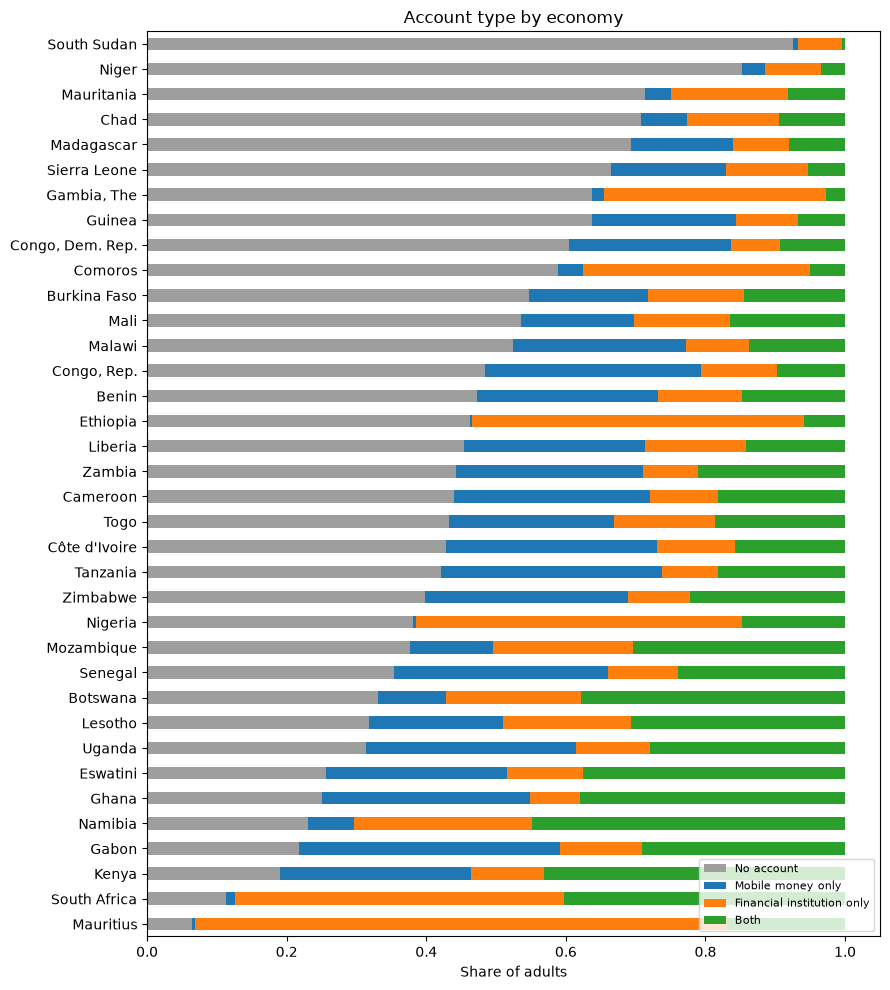

In [5]:
by_country = (pd.crosstab(df["economy"], df["target"], normalize="index")
              .rename(columns=dict(enumerate(CLASS_NAMES))).sort_values("No account"))
ax = by_country.plot(kind="barh", stacked=True, figsize=(9, 10), color=["#9e9e9e", "#1f77b4", "#ff7f0e", "#2ca02c"])
ax.set_xlabel("Share of adults")
ax.set_ylabel("")
ax.set_title("Account type by economy")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
save_fig("class_by_country")
plt.show()

**What this shows.** The country makes a huge difference. In South Sudan 92.5% of adults have no account and in Niger 85.2%, while in Mauritius only 6.5% have none and 76.2% are bank-only. Kenya stands out for mobile money (27.4% mobile only, 43.2% both), and in Tanzania 31.6% are mobile only. The model has to learn this country effect, and section 14 tests what happens in countries it has never seen.

## 4. Leakage audit and feature selection

Findex has 128 columns, but many of them would give the answer away. Three kinds of leakage are possible here:

1. **Questions only asked of account owners** (`fin1` to `fin14`: debit cards, deposits, using mobile money...). Even their *missingness* reveals the class.
2. **Questions only asked of people without an account** (`fin11*`, `fin13*`: reasons for not having one).
3. **Questions whose answer codes mention an account.** For example `receive_wages = 1` means "received wages *into an account*", and `pay_utilities = 1` means "paid *from an account*". The same is true of `fin27*`, `fin29*`, `fin31*`, `fin34*`, `fin39*`, `fin43*`, `fin17a`, `fin22a`, `anydigpayment` and `merchantpay_dig`.

So I only keep questions that describe the person and what they do, **not how they do it**: demographics, phone and internet access, whether they received wages or transfers at all (`fin32`, `fin37`, `fin38`, `fin42`), whether they paid bills or sent/received remittances at all (`fin30`, `fin26`, `fin28`), informal saving and borrowing, and financial worries. The audit below then checks each kept feature: if how often it is missing differs a lot between classes, it would still leak through the survey's skip logic, so it is dropped.

In [6]:
YES_NO = {1: 1.0, 2: 0.0}           # 3 = don't know, 4 = refused -> missing
WORRY = {1: 2.0, 2: 1.0, 3: 0.0, 4: 0.0}  # very / somewhat / not worried / does not apply


def clean_columns(d):
    out = pd.DataFrame(index=d.index)
    out["economy"] = d["economy"].astype(str)
    out["female"] = d["female"].map({1: 1.0, 2: 0.0})
    out["age"] = pd.to_numeric(d["age"], errors="coerce")
    out["educ"] = d["educ"].where(d["educ"].isin([1, 2, 3]))
    out["inc_q"] = d["inc_q"].where(d["inc_q"].between(1, 5))
    out["emp_in"] = d["emp_in"].map({1: 1.0, 2: 0.0})
    out["urbanicity"] = d["urbanicity_f2f"].map({1: "rural", 2: "urban"}).fillna("not asked (phone survey)")
    out["pop_adult"] = pd.to_numeric(d["pop_adult"], errors="coerce")
    for col in ["mobileowner", "internetaccess", "fin16", "fin17b", "fin20", "fin22b", "fin22c",
                "fin26", "fin28", "fin30", "fin32", "fin37", "fin38", "fin42"]:
        out[col] = d[col].map(YES_NO)
    out["fin42a"] = d["fin42a"].map({1: 1.0, 2: 0.0, 3: 1.0})
    out["saved"] = d["saved"].astype(float)
    out["borrowed"] = d["borrowed"].astype(float)
    out["fin24"] = d["fin24"].map({1: "savings", 2: "family or friends", 3: "money from working",
                                   4: "borrowing (bank/employer/lender)", 5: "selling assets",
                                   6: "other source", 7: "could not come up with it"}).fillna("unknown")
    out["fin24a"] = d["fin24a"].map({1: 2.0, 2: 1.0, 3: 0.0})
    for col in ["fin44a", "fin44b", "fin44c", "fin44d"]:
        out[col] = d[col].map(WORRY)
    out["fin45"] = d["fin45"].map({1: "old age", 2: "medical cost", 3: "bills", 4: "education"}).fillna("unknown")
    return out


clean = clean_columns(df)
target = df["target"]

audit = clean.isna().groupby(target).mean().T
audit.columns = CLASS_NAMES
audit["max_gap"] = audit.max(axis=1) - audit.min(axis=1)
audit = audit.sort_values("max_gap", ascending=False)
display(audit.round(3).head(15))

LEAK_THRESHOLD = 0.10
leaky = audit.index[audit["max_gap"] > LEAK_THRESHOLD].tolist()
print("Dropped because missingness depends on the class:", leaky if leaky else "none")
clean = clean.drop(columns=leaky)

,No account,Mobile money only,Financial institution only,Both,max_gap
fin22c,0.835,0.722,0.746,0.639,0.196
fin24a,0.218,0.112,0.114,0.058,0.160
fin42a,0.771,0.748,0.811,0.748,0.063
fin44c,0.018,0.007,0.008,0.003,0.015
fin44a,0.018,0.008,0.011,0.005,0.013
internetaccess,0.013,0.003,0.005,0.001,0.012
fin44b,0.013,0.004,0.010,0.004,0.010
fin30,0.013,0.005,0.005,0.003,0.009
fin44d,0.012,0.003,0.006,0.003,0.009
fin26,0.008,0.002,0.005,0.003,0.007


Dropped because missingness depends on the class: ['fin22c', 'fin24a']


**What this shows.** Two features failed the audit. `fin22c` (borrowed from an informal savings club) is missing for 83.5% of people with no account but only 63.9% of people with both account types, and `fin24a` (difficulty raising emergency funds) is missing for 21.8% versus 5.8%. Keeping them would let the model read the survey's skip pattern instead of the person. `fin42a` (grows crops) is missing for most people in every class (gap 6.3 points) because only some countries asked it, so it stays.

## 5. Feature engineering and the preprocessing pipeline

On top of the cleaned survey answers I add a few features that summarise behaviour in a way the models cannot easily build themselves:

- `digital_access` (0 to 2): owns a mobile phone + has internet access. Mobile money depends on a phone, so this should separate class 1 from class 0.
- `income_flows` (0 to 4): how many kinds of payment the person receives (wages, government transfer, pension, agricultural sales). More payment flows means more reasons to need an account.
- `informal_finance` (0/1): saves in an informal club or borrows from family/an informal club. This is a sign of financial activity *outside* formal accounts.
- `worry_index`: average of the four financial worry questions.
- `age_group`: age bands, so linear models can capture the non-linear age effect.
- `country_phone_rate`, `country_internet_rate`: share of adults in the same economy who own a phone / have internet. These describe the country's digital infrastructure. They are computed **from the training rows only** inside the pipeline, so nothing from validation or test leaks in.
- `log_pop_adult`: size of the economy's adult population.

All of this lives in one scikit-learn transformer (`FindexFeatures`) followed by a `ColumnTransformer`, so exactly the same steps are applied to train, validation and test data and to new data later. Missing numeric values are filled with the training median, missing binary values with the most frequent value, numeric features are standardised, and categories are one-hot encoded.

In [7]:
def present(X, cols):
    # the leakage audit may have dropped some of these, so only use the ones still there
    return [c for c in cols if c in X.columns]


class FindexFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, engineered=True):
        self.engineered = engineered

    def fit(self, X, y=None):
        self.country_rates_ = X.groupby("economy")[["mobileowner", "internetaccess"]].mean()
        self.global_rates_ = X[["mobileowner", "internetaccess"]].mean()
        return self

    def transform(self, X):
        X = X.copy()
        if not self.engineered:
            return X.drop(columns=["pop_adult"])
        X["digital_access"] = X["mobileowner"].fillna(0) + X["internetaccess"].fillna(0)
        X["income_flows"] = X[present(X, ["fin32", "fin37", "fin38", "fin42"])].fillna(0).sum(axis=1)
        X["informal_finance"] = X[present(X, ["fin17b", "fin22b", "fin22c"])].fillna(0).max(axis=1)
        X["worry_index"] = X[present(X, ["fin44a", "fin44b", "fin44c", "fin44d"])].mean(axis=1)
        X["age_group"] = pd.cut(X["age"], bins=[0, 24, 34, 49, 120],
                                labels=["15-24", "25-34", "35-49", "50+"]).astype(str)
        rates = self.country_rates_.reindex(X["economy"])
        X["country_phone_rate"] = rates["mobileowner"].fillna(self.global_rates_["mobileowner"]).values
        X["country_internet_rate"] = rates["internetaccess"].fillna(self.global_rates_["internetaccess"]).values
        X["log_pop_adult"] = np.log10(X["pop_adult"])
        return X.drop(columns=["pop_adult"])


ENGINEERED = ["digital_access", "income_flows", "informal_finance", "worry_index", "age_group",
              "country_phone_rate", "country_internet_rate", "log_pop_adult"]
CATEGORICAL_BASE = ["economy", "urbanicity", "fin24", "fin45"]


def column_groups(columns, engineered=True):
    cats = [c for c in CATEGORICAL_BASE if c in columns] + (["age_group"] if engineered else [])
    numeric = [c for c in ["age", "educ", "inc_q", "fin24a", "fin44a", "fin44b", "fin44c", "fin44d"] if c in columns]
    if engineered:
        numeric += ["digital_access", "income_flows", "worry_index", "country_phone_rate",
                    "country_internet_rate", "log_pop_adult"]
    binary = [c for c in columns if c not in cats + numeric + ["pop_adult", "economy"] and c not in ENGINEERED]
    if engineered:
        binary += ["informal_finance"]
    return numeric, binary, cats


def make_preprocessor(columns, engineered=True, drop_economy=False):
    numeric, binary, cats = column_groups(columns, engineered)
    if drop_economy:
        cats = [c for c in cats if c != "economy"]
    column_tf = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
        ("bin", SimpleImputer(strategy="most_frequent"), binary),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats),
    ])
    return Pipeline([("features", FindexFeatures(engineered=engineered)), ("columns", column_tf)])


print("Columns going into the pipeline:", list(clean.columns))

Columns going into the pipeline: ['economy', 'female', 'age', 'educ', 'inc_q', 'emp_in', 'urbanicity', 'pop_adult', 'mobileowner', 'internetaccess', 'fin16', 'fin17b', 'fin20', 'fin22b', 'fin26', 'fin28', 'fin30', 'fin32', 'fin37', 'fin38', 'fin42', 'fin42a', 'saved', 'borrowed', 'fin24', 'fin44a', 'fin44b', 'fin44c', 'fin44d', 'fin45']


## 6. Data splits

Stratified 70 / 15 / 15 split by class, seed 42:

- **Train** is used to fit every model, and for cross-validated hyperparameter searches.
- **Validation** is used to compare experiments and choose the best model of each paradigm.
- **Test** is used once, at the end, for the two chosen models.

Stratifying keeps the rare classes in the same proportion in every split.

In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(clean, target, test_size=0.30, stratify=target, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

split_table = pd.DataFrame({split: y.value_counts(normalize=True).sort_index().round(3).values
                            for split, y in [("train", y_train), ("validation", y_val), ("test", y_test)]},
                           index=CLASS_NAMES)
split_table.loc["rows"] = [len(y_train), len(y_val), len(y_test)]
display(split_table)

,train,validation,test
No account,0.457,0.457,0.457
Mobile money only,0.177,0.177,0.177
Financial institution only,0.178,0.178,0.178
Both,0.188,0.188,0.188
rows,25243.000,5409.000,5410.000


**What this shows.** The class shares are identical in all three splits (45.7 / 17.7 / 17.8 / 18.8%), so validation and test scores can be compared directly.

## 7. Experiment tracking

Every experiment, ML or DL, goes through the same `record()` helper so the experiment table and TensorBoard always agree:

- the hyperparameters are written to TensorBoard's **HParams** dashboard,
- train and validation metrics are written as scalars (`train/macro_f1`, `val/macro_f1`, ...),
- deep learning runs also log per-epoch loss and accuracy through the Keras TensorBoard callback,
- everything is appended to `results/experiments.csv`.

**Metric choice.** The classes are imbalanced, so plain accuracy would reward a model that ignores the small classes. My main metric is **macro F1** (each class counts equally). I also report balanced accuracy, accuracy and macro ROC-AUC (one-vs-rest).

In [9]:
RESULTS_PATH = os.path.join(RESULTS_DIR, "experiments.csv")
HPARAMS = [hp.HParam(n) for n in ["paradigm", "model", "params"]]
METRICS = ["macro_f1", "balanced_acc", "accuracy", "macro_auc"]
with tf.summary.create_file_writer(LOG_DIR).as_default():
    hp.hparams_config(hparams=HPARAMS, metrics=[hp.Metric(f"val/{m}") for m in METRICS])

EXPERIMENTS = []


def scores(y_true, proba):
    pred = proba.argmax(axis=1)
    return {"macro_f1": f1_score(y_true, pred, average="macro"),
            "balanced_acc": balanced_accuracy_score(y_true, pred),
            "accuracy": accuracy_score(y_true, pred),
            "macro_auc": roc_auc_score(y_true, proba, multi_class="ovr", average="macro")}


def record(run_id, paradigm, model_name, change, params, train_proba, val_proba, fit_seconds, note=""):
    tr, va = scores(y_train_used(run_id), train_proba), scores(y_val, val_proba)
    row = {"id": run_id, "paradigm": paradigm, "model": model_name, "change": change,
           "params": json.dumps(params, default=str), "split": "train 70% / val 15% (stratified, seed 42)",
           **{f"train_{k}": round(v, 4) for k, v in tr.items()},
           **{f"val_{k}": round(v, 4) for k, v in va.items()},
           "gap_macro_f1": round(tr["macro_f1"] - va["macro_f1"], 4), "fit_seconds": round(fit_seconds, 1),
           "note": note}
    with tf.summary.create_file_writer(os.path.join(LOG_DIR, run_id)).as_default():
        hp.hparams({"paradigm": paradigm, "model": model_name, "params": json.dumps(params, default=str)[:250]},
                   trial_id=run_id)
        for k in METRICS:
            tf.summary.scalar(f"train/{k}", tr[k], step=0)
            tf.summary.scalar(f"val/{k}", va[k], step=0)
    EXPERIMENTS[:] = [e for e in EXPERIMENTS if e["id"] != run_id] + [row]
    pd.DataFrame(EXPERIMENTS).to_csv(RESULTS_PATH, index=False)
    print(f"{run_id}: val macro-F1 {va['macro_f1']:.4f} | bal-acc {va['balanced_acc']:.4f} | "
          f"acc {va['accuracy']:.4f} | AUC {va['macro_auc']:.4f} | train-val F1 gap {row['gap_macro_f1']:+.4f} "
          f"| {fit_seconds:.0f}s")
    return row


TRAIN_LABELS = {}


def y_train_used(run_id):
    return TRAIN_LABELS.get(run_id, y_train)

## 8. Traditional machine learning experiments

Each run changes one thing from an earlier one, so differences can be explained. The plan:

| Run | Model | Change | Why |
|---|---|---|---|
| ML-01 | Dummy (stratified guess) | baseline floor | Any real model must beat this |
| ML-02 | Logistic regression | raw cleaned features only | Simple, interpretable starting point |
| ML-03 | Logistic regression | + engineered features | Do my features add signal? |
| ML-04 | Logistic regression | + balanced class weights, C tuned by 3-fold CV | Help the small classes |
| ML-05 | Random forest | default settings, engineered features | Non-linear interactions |
| ML-06 | Random forest | randomised search (depth, leaves, features, class weights) | Control overfitting |
| ML-07 | Histogram gradient boosting | default settings | Usually strongest on tabular data |
| ML-08 | Histogram gradient boosting | randomised search + balanced class weights | Tune the best family |
| ML-09 | SVM (RBF kernel) | balanced weights, C tuned, 10k-row training subsample | Different decision boundary; cost check |
| ML-10 | Gradient boosting (ML-08 settings) | only the top features by permutation importance | Is a smaller, more interpretable model as good? |
| ML-11 | Gradient boosting (ML-08 settings) | raw features only, no engineered features | Ablation: do my engineered features help the best model family? |
| ML-12 | Gradient boosting (default) | **all** 128 survey columns, leaks included | Not a candidate: shows what the leakage audit protects against |

In [10]:
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
FITTED = {}


def run_ml(run_id, model_name, change, estimator, params_for_table, engineered=True, search=None,
           X_tr=None, y_tr=None, note=""):
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    pipe = Pipeline([("prep", make_preprocessor(X_tr.columns, engineered=engineered)), ("model", estimator)])
    start = time.time()
    if search is not None:
        searcher = search(pipe)
        searcher.fit(X_tr, y_tr)
        pipe = searcher.best_estimator_
        params_for_table = {**params_for_table, **{k.replace("model__", ""): v for k, v in searcher.best_params_.items()}}
    else:
        pipe.fit(X_tr, y_tr)
    seconds = time.time() - start
    TRAIN_LABELS[run_id] = y_tr
    FITTED[run_id] = pipe
    return record(run_id, "ML", model_name, change, params_for_table, pipe.predict_proba(X_tr),
                  pipe.predict_proba(X_val), seconds, note)

In [11]:
run_ml("ML-01_dummy_stratified", "DummyClassifier", "baseline: random guess in class proportions",
       DummyClassifier(strategy="stratified", random_state=SEED), {"strategy": "stratified"})

run_ml("ML-02_logreg_raw", "LogisticRegression", "raw cleaned features, no engineering",
       LogisticRegression(max_iter=3000, C=1.0), {"C": 1.0, "class_weight": None, "features": "raw"},
       engineered=False)

run_ml("ML-03_logreg_engineered", "LogisticRegression", "+ engineered features",
       LogisticRegression(max_iter=3000, C=1.0), {"C": 1.0, "class_weight": None, "features": "engineered"})

run_ml("ML-04_logreg_balanced_tuned", "LogisticRegression", "+ balanced class weights, C tuned (3-fold CV)",
       LogisticRegression(max_iter=3000, class_weight="balanced"), {"class_weight": "balanced", "features": "engineered"},
       search=lambda p: GridSearchCV(p, {"model__C": [0.01, 0.1, 1.0, 10.0]}, scoring="f1_macro", cv=CV, n_jobs=-1))

ML-01_dummy_stratified: val macro-F1 0.2484 | bal-acc 0.2484 | acc 0.3041 | AUC 0.4991 | train-val F1 gap +0.0008 | 0s


ML-02_logreg_raw: val macro-F1 0.5843 | bal-acc 0.5754 | acc 0.6559 | AUC 0.8401 | train-val F1 gap -0.0021 | 1s


ML-03_logreg_engineered: val macro-F1 0.5799 | bal-acc 0.5716 | acc 0.6517 | AUC 0.8408 | train-val F1 gap +0.0028 | 1s


ML-04_logreg_balanced_tuned: val macro-F1 0.5868 | bal-acc 0.5971 | acc 0.6214 | AUC 0.8386 | train-val F1 gap +0.0038 | 6s


{'id': 'ML-04_logreg_balanced_tuned',
 'paradigm': 'ML',
 'model': 'LogisticRegression',
 'change': '+ balanced class weights, C tuned (3-fold CV)',
 'params': '{"class_weight": "balanced", "features": "engineered", "C": 1.0}',
 'split': 'train 70% / val 15% (stratified, seed 42)',
 'train_macro_f1': 0.5905,
 'train_balanced_acc': 0.6028,
 'train_accuracy': 0.6249,
 'train_macro_auc': 0.8494,
 'val_macro_f1': 0.5868,
 'val_balanced_acc': 0.5971,
 'val_accuracy': 0.6214,
 'val_macro_auc': 0.8386,
 'gap_macro_f1': 0.0038,
 'fit_seconds': 6.1,
 'note': ''}

**What this shows.** Logistic regression jumps from the chance level (0.248) to 0.584 validation macro F1. My engineered features did not help it (0.580), because they are sums of columns it can already combine with its own weights. Balanced class weights (ML-04) raised balanced accuracy from 0.572 to 0.597 but lowered accuracy from 0.652 to 0.621: the model now predicts the small classes more often, which is the trade-off I expected.

In [12]:
run_ml("ML-05_rf_default", "RandomForestClassifier", "non-linear model, default settings",
       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
       {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1})

run_ml("ML-06_rf_tuned", "RandomForestClassifier", "randomised search over depth, leaf size, features, class weights",
       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), {"n_estimators": 300},
       search=lambda p: RandomizedSearchCV(p, {
           "model__max_depth": [8, 12, 16, 24, None],
           "model__min_samples_leaf": [1, 3, 5, 10, 20],
           "model__max_features": ["sqrt", 0.3, 0.5],
           "model__class_weight": [None, "balanced", "balanced_subsample"]},
           n_iter=12, scoring="f1_macro", cv=CV, random_state=SEED, n_jobs=-1))

ML-05_rf_default: val macro-F1 0.5606 | bal-acc 0.5509 | acc 0.6408 | AUC 0.8317 | train-val F1 gap +0.4394 | 2s


ML-06_rf_tuned: val macro-F1 0.5871 | bal-acc 0.5917 | acc 0.6295 | AUC 0.8360 | train-val F1 gap +0.1286 | 55s


{'id': 'ML-06_rf_tuned',
 'paradigm': 'ML',
 'model': 'RandomForestClassifier',
 'change': 'randomised search over depth, leaf size, features, class weights',
 'params': '{"n_estimators": 300, "min_samples_leaf": 5, "max_features": "sqrt", "max_depth": 16, "class_weight": "balanced_subsample"}',
 'split': 'train 70% / val 15% (stratified, seed 42)',
 'train_macro_f1': 0.7157,
 'train_balanced_acc': 0.7271,
 'train_accuracy': 0.7402,
 'train_macro_auc': 0.9361,
 'val_macro_f1': 0.5871,
 'val_balanced_acc': 0.5917,
 'val_accuracy': 0.6295,
 'val_macro_auc': 0.836,
 'gap_macro_f1': 0.1286,
 'fit_seconds': 55.0,
 'note': ''}

**What this shows.** The default random forest (ML-05) is a textbook case of overfitting: 1.000 macro F1 on training but 0.561 on validation. The search chose a maximum depth of 16, at least 5 samples per leaf and balanced subsample weights, which cut the gap from 0.439 to 0.129 and raised validation F1 to 0.587.

In [13]:
run_ml("ML-07_hgb_default", "HistGradientBoostingClassifier", "gradient boosting, default settings",
       HistGradientBoostingClassifier(random_state=SEED), {"learning_rate": 0.1, "max_leaf_nodes": 31, "max_iter": 100})

run_ml("ML-08_hgb_tuned", "HistGradientBoostingClassifier", "randomised search + balanced class weights",
       HistGradientBoostingClassifier(random_state=SEED, early_stopping=True, max_iter=500, class_weight="balanced"),
       {"class_weight": "balanced", "early_stopping": True},
       search=lambda p: RandomizedSearchCV(p, {
           "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
           "model__max_leaf_nodes": [15, 31, 63],
           "model__min_samples_leaf": [20, 50, 100],
           "model__l2_regularization": [0.0, 0.1, 1.0],
           "model__max_features": [0.5, 0.8, 1.0]},
           n_iter=20, scoring="f1_macro", cv=CV, random_state=SEED, n_jobs=-1))

ML-07_hgb_default: val macro-F1 0.5815 | bal-acc 0.5732 | acc 0.6493 | AUC 0.8407 | train-val F1 gap +0.0789 | 4s


ML-08_hgb_tuned: val macro-F1 0.5858 | bal-acc 0.5954 | acc 0.6223 | AUC 0.8411 | train-val F1 gap +0.0843 | 106s


{'id': 'ML-08_hgb_tuned',
 'paradigm': 'ML',
 'model': 'HistGradientBoostingClassifier',
 'change': 'randomised search + balanced class weights',
 'params': '{"class_weight": "balanced", "early_stopping": true, "min_samples_leaf": 20, "max_leaf_nodes": 31, "max_features": 0.5, "learning_rate": 0.03, "l2_regularization": 1.0}',
 'split': 'train 70% / val 15% (stratified, seed 42)',
 'train_macro_f1': 0.6702,
 'train_balanced_acc': 0.6843,
 'train_accuracy': 0.6975,
 'train_macro_auc': 0.9044,
 'val_macro_f1': 0.5858,
 'val_balanced_acc': 0.5954,
 'val_accuracy': 0.6223,
 'val_macro_auc': 0.8411,
 'gap_macro_f1': 0.0843,
 'fit_seconds': 106.1,
 'note': ''}

**What this shows.** Gradient boosting overfits far less than the random forest out of the box (gap 0.079). Tuning it (learning rate 0.03, L2 regularisation, 50% of features per split, balanced weights) raised balanced accuracy from 0.573 to 0.595, but macro F1 only from 0.582 to 0.586.

In [14]:
svm_idx = X_train.sample(n=min(10000, len(X_train)), random_state=SEED).index
run_ml("ML-09_svm_rbf_subsample", "SVC (RBF)", "different model family, balanced weights, C tuned on 10k rows",
       SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=SEED),
       {"kernel": "rbf", "class_weight": "balanced", "train_rows": len(svm_idx)},
       X_tr=X_train.loc[svm_idx], y_tr=y_train.loc[svm_idx],
       search=lambda p: GridSearchCV(p, {"model__C": [0.3, 1.0, 3.0]}, scoring="f1_macro", cv=CV, n_jobs=-1),
       note="trained on a 10k-row subsample because SVC training time grows roughly with n^2")

/Users/igaime/Development/ALU/2026/Summative_Findex/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/igaime/Development/ALU/2026/Summative_Findex/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/igaime/Development/ALU/2026/Summative_Findex/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/igaime/Development/ALU/2026/Summativ

/Users/igaime/Development/ALU/2026/Summative_Findex/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/igaime/Development/ALU/2026/Summative_Findex/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/igaime/Development/ALU/2026/Summative_Findex/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


ML-09_svm_rbf_subsample: val macro-F1 0.5664 | bal-acc 0.5597 | acc 0.6399 | AUC 0.8277 | train-val F1 gap +0.1377 | 61s


{'id': 'ML-09_svm_rbf_subsample',
 'paradigm': 'ML',
 'model': 'SVC (RBF)',
 'change': 'different model family, balanced weights, C tuned on 10k rows',
 'params': '{"kernel": "rbf", "class_weight": "balanced", "train_rows": 10000, "C": 1.0}',
 'split': 'train 70% / val 15% (stratified, seed 42)',
 'train_macro_f1': 0.7041,
 'train_balanced_acc': 0.6932,
 'train_accuracy': 0.7472,
 'train_macro_auc': 0.9134,
 'val_macro_f1': 0.5664,
 'val_balanced_acc': 0.5597,
 'val_accuracy': 0.6399,
 'val_macro_auc': 0.8277,
 'gap_macro_f1': 0.1377,
 'fit_seconds': 60.6,
 'note': 'trained on a 10k-row subsample because SVC training time grows roughly with n^2'}

**What this shows.** The SVM was the weakest real model (0.566) and the most expensive per row. Part of that is the 10,000-row subsample, but it also overfits more (gap 0.138), so it is not worth its cost here.

**ML-10: feature selection.** I use permutation importance of the tuned gradient boosting model on the validation set: shuffle one input column at a time and measure how much macro F1 drops. Then I retrain the same model using only the features that matter. If the score barely changes, the smaller model is preferable because it is faster and easier to explain to non-technical partners.

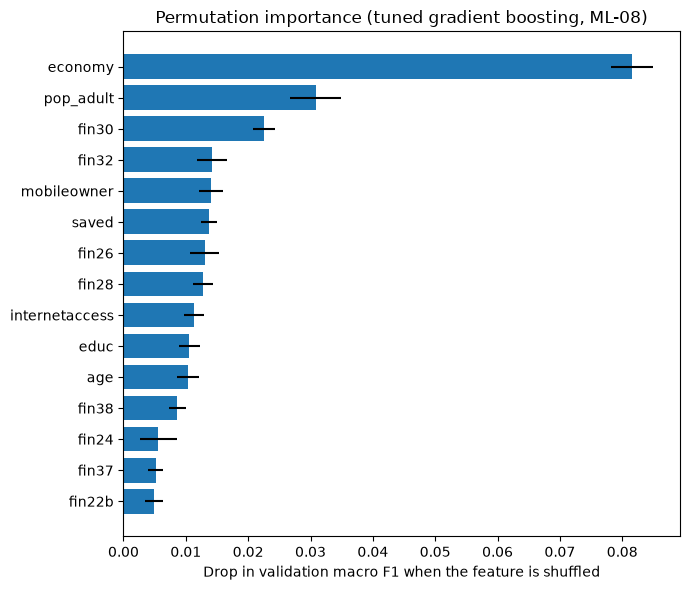

Keeping 24 of 30 input columns (plus the engineered features they feed)
Dropped as unimportant: ['female', 'emp_in', 'urbanicity', 'fin20', 'fin42a', 'fin45']


ML-10_hgb_selected_features: val macro-F1 0.5932 | bal-acc 0.6027 | acc 0.6275 | AUC 0.8406 | train-val F1 gap +0.0651 | 16s


{'id': 'ML-10_hgb_selected_features',
 'paradigm': 'ML',
 'model': 'HistGradientBoostingClassifier',
 'change': 'ML-08 settings, permutation-selected features only',
 'params': '{"l2_regularization": 1.0, "learning_rate": 0.03, "max_features": 0.5, "max_leaf_nodes": 31, "min_samples_leaf": 20, "n_input_columns": 24}',
 'split': 'train 70% / val 15% (stratified, seed 42)',
 'train_macro_f1': 0.6582,
 'train_balanced_acc': 0.6723,
 'train_accuracy': 0.6863,
 'train_macro_auc': 0.896,
 'val_macro_f1': 0.5932,
 'val_balanced_acc': 0.6027,
 'val_accuracy': 0.6275,
 'val_macro_auc': 0.8406,
 'gap_macro_f1': 0.0651,
 'fit_seconds': 15.9,
 'note': ''}

In [15]:
hgb_tuned = FITTED["ML-08_hgb_tuned"]
perm = permutation_importance(hgb_tuned, X_val, y_val, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_val.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 6))
top = importance.head(15)[::-1]
ax.barh(top.index, top.values, xerr=pd.Series(perm.importances_std, index=X_val.columns)[top.index], color="#1f77b4")
ax.set_xlabel("Drop in validation macro F1 when the feature is shuffled")
ax.set_title("Permutation importance (tuned gradient boosting, ML-08)")
plt.tight_layout()
save_fig("permutation_importance")
plt.show()

selected = importance[importance > 0.002].index.tolist()
for needed in ["economy", "mobileowner", "internetaccess", "pop_adult", "fin32", "fin37", "fin38", "fin42",
               "fin17b", "fin22b", "fin22c", "fin44a", "fin44b", "fin44c", "fin44d", "age"]:
    if needed in X_val.columns and needed not in selected:
        selected.append(needed)
print(f"Keeping {len(selected)} of {X_val.shape[1]} input columns (plus the engineered features they feed)")
print("Dropped as unimportant:", [c for c in X_val.columns if c not in selected])

best_hgb_params = {k.replace("model__", ""): v for k, v in hgb_tuned.get_params().items()
                   if k.startswith("model__") and k.split("__")[1] in
                   ["learning_rate", "max_leaf_nodes", "min_samples_leaf", "l2_regularization", "max_features"]}
X_train_sel, X_val_sel = X_train[selected], X_val[selected]


def run_ml_selected():
    pipe = Pipeline([("prep", make_preprocessor(X_train_sel.columns)),
                     ("model", HistGradientBoostingClassifier(random_state=SEED, early_stopping=True, max_iter=500,
                                                              class_weight="balanced", **best_hgb_params))])
    start = time.time()
    pipe.fit(X_train_sel, y_train)
    FITTED["ML-10_hgb_selected_features"] = pipe
    return record("ML-10_hgb_selected_features", "ML", "HistGradientBoostingClassifier",
                  "ML-08 settings, permutation-selected features only",
                  {**best_hgb_params, "n_input_columns": len(selected)},
                  pipe.predict_proba(X_train_sel), pipe.predict_proba(X_val_sel), time.time() - start)


run_ml_selected()

**What this shows.** The country (`economy`) is by far the most important input, followed by the country's adult population, paying a utility bill (`fin30`), receiving wages (`fin32`), phone ownership and saving. Six columns had almost no importance: gender, labour force participation, rural/urban, borrowing for medical reasons, growing crops and the main financial worry. Dropping them (ML-10) gave the best validation macro F1 so far, 0.593, with a smaller train-validation gap (0.065 vs 0.084), so the simpler model is also the better one.

**ML-11: feature engineering ablation.** Logistic regression did not gain from my engineered features (ML-02 vs ML-03). That makes sense: `digital_access` or `income_flows` are sums of columns the linear model already sees, so it can build them itself. Trees cannot add columns together inside one split, so the engineered features may matter more there. To test this properly, I retrain the tuned gradient boosting model (ML-08 settings) on the raw cleaned features only.

In [16]:
def run_ml_raw_ablation():
    pipe = Pipeline([("prep", make_preprocessor(X_train.columns, engineered=False)),
                     ("model", HistGradientBoostingClassifier(random_state=SEED, early_stopping=True, max_iter=500,
                                                              class_weight="balanced", **best_hgb_params))])
    start = time.time()
    pipe.fit(X_train, y_train)
    FITTED["ML-11_hgb_tuned_raw_features"] = pipe
    return record("ML-11_hgb_tuned_raw_features", "ML", "HistGradientBoostingClassifier",
                  "ablation: ML-08 settings without the engineered features",
                  {**best_hgb_params, "features": "raw"},
                  pipe.predict_proba(X_train), pipe.predict_proba(X_val), time.time() - start)


run_ml_raw_ablation()

ML-11_hgb_tuned_raw_features: val macro-F1 0.5864 | bal-acc 0.5961 | acc 0.6221 | AUC 0.8417 | train-val F1 gap +0.0636 | 21s


{'id': 'ML-11_hgb_tuned_raw_features',
 'paradigm': 'ML',
 'model': 'HistGradientBoostingClassifier',
 'change': 'ablation: ML-08 settings without the engineered features',
 'params': '{"l2_regularization": 1.0, "learning_rate": 0.03, "max_features": 0.5, "max_leaf_nodes": 31, "min_samples_leaf": 20, "features": "raw"}',
 'split': 'train 70% / val 15% (stratified, seed 42)',
 'train_macro_f1': 0.6499,
 'train_balanced_acc': 0.6641,
 'train_accuracy': 0.6784,
 'train_macro_auc': 0.8921,
 'val_macro_f1': 0.5864,
 'val_balanced_acc': 0.5961,
 'val_accuracy': 0.6221,
 'val_macro_auc': 0.8417,
 'gap_macro_f1': 0.0636,
 'fit_seconds': 20.6,
 'note': ''}

**What this shows.** Without the engineered features, the tuned model scores 0.586, exactly the same as with them (ML-08). So for both model families the engineered features did not add accuracy. They still help explain the model, because they turn several survey answers into one readable idea, but the accuracy gain came from feature *selection*, not feature engineering.

**ML-12: what happens without the leakage audit.** This run is *not* a candidate model. It trains default gradient boosting on every Findex column except the target itself (questions only asked to account owners, reasons for not having an account, "received wages into an account", and so on), with missing values kept visible to the model. If the score jumps far above every honest run, it confirms that those columns encode the answer rather than predict it, and that a model built on them would be useless in practice: you cannot ask someone why they have no account before you know they have none.

In [17]:
not_features = ["target", "account", "account_fin", "account_mob", "economy", "economycode", "regionwb",
                "wpid_random", "wgt", "year"]
X_leaky = df[[c for c in df.columns if c not in not_features]].apply(pd.to_numeric, errors="coerce")
leaky_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value=-1)),
                       ("model", HistGradientBoostingClassifier(random_state=SEED))])
start = time.time()
leaky_pipe.fit(X_leaky.loc[X_train.index], y_train)
record("ML-12_leakage_demo_all_columns", "ML", "HistGradientBoostingClassifier",
       "NOT A CANDIDATE: all survey columns including leaky ones", {"n_columns": X_leaky.shape[1]},
       leaky_pipe.predict_proba(X_leaky.loc[X_train.index]), leaky_pipe.predict_proba(X_leaky.loc[X_val.index]),
       time.time() - start, note="demonstrates leakage; excluded from model selection")

ML-12_leakage_demo_all_columns: val macro-F1 0.9995 | bal-acc 0.9995 | acc 0.9996 | AUC 1.0000 | train-val F1 gap +0.0004 | 5s


{'id': 'ML-12_leakage_demo_all_columns',
 'paradigm': 'ML',
 'model': 'HistGradientBoostingClassifier',
 'change': 'NOT A CANDIDATE: all survey columns including leaky ones',
 'params': '{"n_columns": 119}',
 'split': 'train 70% / val 15% (stratified, seed 42)',
 'train_macro_f1': 0.9999,
 'train_balanced_acc': 0.9999,
 'train_accuracy': 0.9999,
 'train_macro_auc': 1.0,
 'val_macro_f1': 0.9995,
 'val_balanced_acc': 0.9995,
 'val_accuracy': 0.9996,
 'val_macro_auc': 1.0,
 'gap_macro_f1': 0.0004,
 'fit_seconds': 5.0,
 'note': 'demonstrates leakage; excluded from model selection'}

**What this shows.** With every column, the model reaches 0.9995 validation macro F1 and an AUC of 1.000. That is not skill: questions asked only of account holders (or only of people without one) hand the answer to the model. This is the clearest evidence that the leakage audit in section 4 was necessary. The run is excluded from model selection.

## 9. Deep learning experiments (Keras Functional API + tf.data)

The neural networks use the same preprocessing pipeline (fitted on the training rows only) so the comparison with ML is fair. Data is fed through `tf.data` pipelines (shuffle, batch, prefetch). Every network is built with the **Functional API**, which also lets DL-04 take the economy as a separate input and learn an **embedding** for it instead of a one-hot vector.

Training uses Adam, sparse categorical cross-entropy, and early stopping on validation loss (patience 8, best weights restored). Each run logs its epoch curves to TensorBoard.

| Run | Change from parent | Why |
|---|---|---|
| DL-01 | MLP, one hidden layer of 64, no regularisation | Baseline |
| DL-02 | two layers (128, 64) + batch norm + dropout 0.3 | More capacity, regularised |
| DL-03 | + balanced class weights | Same reason as ML-04: small classes |
| DL-04 | economy as a learned 8-dim embedding (two-input model) | Let the network learn country similarity |
| DL-05 | learning rate 3e-4 + reduce-on-plateau + L2 1e-4 | Smoother convergence |
| DL-06 | wider (256, 128, 64), dropout 0.4 | Does more capacity help? |
| DL-07 | learning rate 1e-2 | Stress test: what does a too-high learning rate do? |

In [18]:
dl_prep = make_preprocessor(X_train.columns)
Xtr_dl = dl_prep.fit_transform(X_train).astype("float32")
Xva_dl = dl_prep.transform(X_val).astype("float32")
Xte_dl = dl_prep.transform(X_test).astype("float32")

dl_prep_noecon = make_preprocessor(X_train.columns, drop_economy=True)
Xtr_ne = dl_prep_noecon.fit_transform(X_train).astype("float32")
Xva_ne = dl_prep_noecon.transform(X_val).astype("float32")
Xte_ne = dl_prep_noecon.transform(X_test).astype("float32")

ECONOMIES = sorted(X_train["economy"].unique())
ECON_INDEX = {e: i + 1 for i, e in enumerate(ECONOMIES)}  # 0 is kept for unseen economies


def econ_ids(X):
    return X["economy"].map(ECON_INDEX).fillna(0).astype("int32").values.reshape(-1, 1)


Etr, Eva, Ete = econ_ids(X_train), econ_ids(X_val), econ_ids(X_test)
N_CLASSES = len(CLASS_NAMES)
CLASS_WEIGHTS = dict(enumerate(compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train)))
print(f"Input features after preprocessing: {Xtr_dl.shape[1]} (one-hot economy) / {Xtr_ne.shape[1]} (economy embedded)")
print("Balanced class weights:", {CLASS_NAMES[k]: round(v, 2) for k, v in CLASS_WEIGHTS.items()})


def make_dataset(X, y=None, econ=None, batch_size=256, shuffle=False):
    inputs = {"features": X} if econ is None else {"features": X, "economy": econ}
    ds = tf.data.Dataset.from_tensor_slices(inputs if y is None else (inputs, y.values))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def build_mlp(n_features, hidden=(64,), dropout=0.0, batchnorm=False, l2=0.0, lr=1e-3, embed_dim=None):
    reg = regularizers.l2(l2) if l2 else None
    features = keras.Input(shape=(n_features,), name="features")
    inputs, x = [features], features
    if embed_dim:
        economy = keras.Input(shape=(1,), dtype="int32", name="economy")
        emb = layers.Flatten()(layers.Embedding(len(ECONOMIES) + 1, embed_dim, name="economy_embedding")(economy))
        inputs.append(economy)
        x = layers.Concatenate()([x, emb])
    for units in hidden:
        x = layers.Dense(units, kernel_regularizer=reg)(x)
        if batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        if dropout:
            x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="findex_mlp")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


DL_HISTORY = {}


def run_dl(run_id, change, hidden=(64,), dropout=0.0, batchnorm=False, l2=0.0, lr=1e-3, embed_dim=None,
           class_weights=False, plateau=False, batch_size=256, epochs=80):
    keras.utils.set_random_seed(SEED)
    use_emb = bool(embed_dim)
    Xtr, Xva = (Xtr_ne, Xva_ne) if use_emb else (Xtr_dl, Xva_dl)
    etr, eva = (Etr, Eva) if use_emb else (None, None)
    model = build_mlp(Xtr.shape[1], hidden, dropout, batchnorm, l2, lr, embed_dim)
    callbacks = [keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_DIR, run_id)),
                 keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)]
    if plateau:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-5))
    start = time.time()
    history = model.fit(make_dataset(Xtr, y_train, etr, batch_size, shuffle=True),
                        validation_data=make_dataset(Xva, y_val, eva, batch_size),
                        epochs=epochs, class_weight=CLASS_WEIGHTS if class_weights else None,
                        callbacks=callbacks, verbose=0)
    seconds = time.time() - start
    DL_HISTORY[run_id] = history.history
    FITTED[run_id] = model
    params = {"hidden": list(hidden), "dropout": dropout, "batchnorm": batchnorm, "l2": l2, "lr": lr,
              "embedding": embed_dim, "class_weights": class_weights, "reduce_on_plateau": plateau,
              "batch_size": batch_size, "epochs_run": len(history.history["loss"]),
              "best_epoch": int(np.argmin(history.history["val_loss"])) + 1}
    return record(run_id, "DL", "Keras MLP (Functional API)", change, params,
                  model.predict(make_dataset(Xtr, None, etr, 1024), verbose=0),
                  model.predict(make_dataset(Xva, None, eva, 1024), verbose=0), seconds)

Input features after preprocessing: 89 (one-hot economy) / 53 (economy embedded)
Balanced class weights: {'No account': np.float64(0.55), 'Mobile money only': np.float64(1.41), 'Financial institution only': np.float64(1.4), 'Both': np.float64(1.33)}


In [19]:
run_dl("DL-01_mlp_baseline", "one hidden layer (64), no regularisation", hidden=(64,))
run_dl("DL-02_mlp_bn_dropout", "two layers (128, 64) + batch norm + dropout 0.3",
       hidden=(128, 64), dropout=0.3, batchnorm=True)
run_dl("DL-03_class_weights", "+ balanced class weights",
       hidden=(128, 64), dropout=0.3, batchnorm=True, class_weights=True)
run_dl("DL-04_economy_embedding", "economy as an 8-dim learned embedding (two inputs)",
       hidden=(128, 64), dropout=0.3, batchnorm=True, class_weights=True, embed_dim=8)
run_dl("DL-05_lr3e-4_plateau_l2", "lr 3e-4 + reduce-on-plateau + L2 1e-4",
       hidden=(128, 64), dropout=0.3, batchnorm=True, class_weights=True, embed_dim=8, lr=3e-4, plateau=True, l2=1e-4)
run_dl("DL-06_wider_256_128_64", "wider network (256, 128, 64), dropout 0.4",
       hidden=(256, 128, 64), dropout=0.4, batchnorm=True, class_weights=True, embed_dim=8, lr=3e-4, plateau=True, l2=1e-4)
run_dl("DL-07_lr1e-2_stress", "learning rate 1e-2 (stress test)",
       hidden=(128, 64), dropout=0.3, batchnorm=True, class_weights=True, embed_dim=8, lr=1e-2)

DL-01_mlp_baseline: val macro-F1 0.5877 | bal-acc 0.5817 | acc 0.6521 | AUC 0.8422 | train-val F1 gap +0.0167 | 2s


DL-02_mlp_bn_dropout: val macro-F1 0.5826 | bal-acc 0.5754 | acc 0.6517 | AUC 0.8427 | train-val F1 gap +0.0397 | 6s


DL-03_class_weights: val macro-F1 0.5866 | bal-acc 0.5953 | acc 0.6256 | AUC 0.8389 | train-val F1 gap +0.0197 | 4s


DL-04_economy_embedding: val macro-F1 0.5853 | bal-acc 0.5960 | acc 0.6204 | AUC 0.8392 | train-val F1 gap +0.0192 | 5s


DL-05_lr3e-4_plateau_l2: val macro-F1 0.5822 | bal-acc 0.5933 | acc 0.6186 | AUC 0.8365 | train-val F1 gap +0.0132 | 7s


DL-06_wider_256_128_64: val macro-F1 0.5830 | bal-acc 0.5955 | acc 0.6138 | AUC 0.8373 | train-val F1 gap +0.0120 | 14s


DL-07_lr1e-2_stress: val macro-F1 0.5849 | bal-acc 0.5878 | acc 0.6256 | AUC 0.8377 | train-val F1 gap +0.0165 | 4s


{'id': 'DL-07_lr1e-2_stress',
 'paradigm': 'DL',
 'model': 'Keras MLP (Functional API)',
 'change': 'learning rate 1e-2 (stress test)',
 'params': '{"hidden": [128, 64], "dropout": 0.3, "batchnorm": true, "l2": 0.0, "lr": 0.01, "embedding": 8, "class_weights": true, "reduce_on_plateau": false, "batch_size": 256, "epochs_run": 15, "best_epoch": 7}',
 'split': 'train 70% / val 15% (stratified, seed 42)',
 'train_macro_f1': 0.6014,
 'train_balanced_acc': 0.6073,
 'train_accuracy': 0.6421,
 'train_macro_auc': 0.8627,
 'val_macro_f1': 0.5849,
 'val_balanced_acc': 0.5878,
 'val_accuracy': 0.6256,
 'val_macro_auc': 0.8377,
 'gap_macro_f1': 0.0165,
 'fit_seconds': 3.8,
 'note': ''}

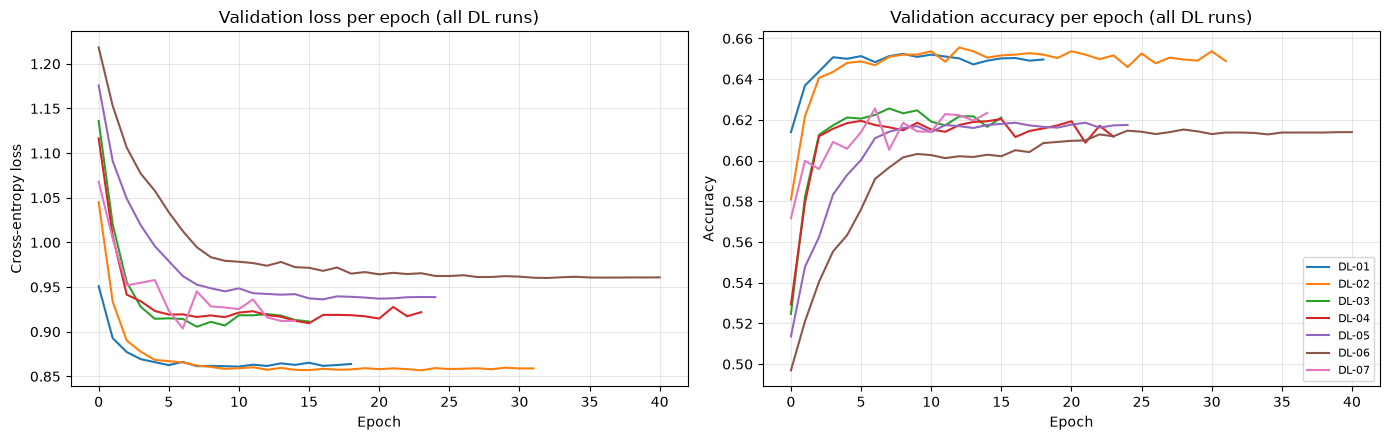

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for run_id, h in DL_HISTORY.items():
    label = run_id.split("_")[0]
    axes[0].plot(h["val_loss"], label=label)
    axes[1].plot(h["val_accuracy"], label=label)
axes[0].set_title("Validation loss per epoch (all DL runs)")
axes[1].set_title("Validation accuracy per epoch (all DL runs)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Cross-entropy loss")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8)
plt.tight_layout()
save_fig("dl_validation_curves")
plt.show()

**What this shows.** The simplest network (DL-01, one hidden layer) has the lowest validation loss and the best validation macro F1 (0.588). Extra layers, batch normalisation and dropout (DL-02), a country embedding (DL-04) or more width (DL-06) did not help, so capacity is not the bottleneck. The class-weighted runs (DL-03 to DL-07) have higher loss and lower accuracy by design, but better balanced accuracy. With a learning rate of 0.01 (DL-07) the validation loss jumps around between epochs and early stopping ends training at epoch 15.

## 10. Experiment table

All runs, ML and DL, on the same split. `gap_macro_f1` is train minus validation macro F1: a large positive gap is overfitting (high variance), low scores on both is underfitting (high bias). Every row has a TensorBoard run with the same id (the last cell shows how to open them).

,id,model,change,train_macro_f1,val_macro_f1,val_balanced_acc,val_accuracy,val_macro_auc,gap_macro_f1,fit_seconds
0,ML-01_dummy_stratified,DummyClassifier,baseline: random guess in class proportions,0.2492,0.2484,0.2484,0.3041,0.4991,0.0008,0.1000
1,ML-02_logreg_raw,LogisticRegression,"raw cleaned features, no engineering",0.5821,0.5843,0.5754,0.6559,0.8401,-0.0021,0.5000
2,ML-03_logreg_engineered,LogisticRegression,+ engineered features,0.5827,0.5799,0.5716,0.6517,0.8408,0.0028,0.6000
3,ML-04_logreg_balanced_tuned,LogisticRegression,"+ balanced class weights, C tuned (3-fold CV)",0.5905,0.5868,0.5971,0.6214,0.8386,0.0038,6.1000
4,ML-05_rf_default,RandomForestClassifier,"non-linear model, default settings",1.0000,0.5606,0.5509,0.6408,0.8317,0.4394,1.7000
5,ML-06_rf_tuned,RandomForestClassifier,"randomised search over depth, leaf size, features, class weights",0.7157,0.5871,0.5917,0.6295,0.8360,0.1286,55.0000
6,ML-07_hgb_default,HistGradientBoostingClassifier,"gradient boosting, default settings",0.6604,0.5815,0.5732,0.6493,0.8407,0.0789,4.1000
7,ML-08_hgb_tuned,HistGradientBoostingClassifier,randomised search + balanced class weights,0.6702,0.5858,0.5954,0.6223,0.8411,0.0843,106.1000
8,ML-09_svm_rbf_subsample,SVC (RBF),"different model family, balanced weights, C tuned on 10k rows",0.7041,0.5664,0.5597,0.6399,0.8277,0.1377,60.6000
9,ML-10_hgb_selected_features,HistGradientBoostingClassifier,"ML-08 settings, permutation-selected features only",0.6582,0.5932,0.6027,0.6275,0.8406,0.0651,15.9000


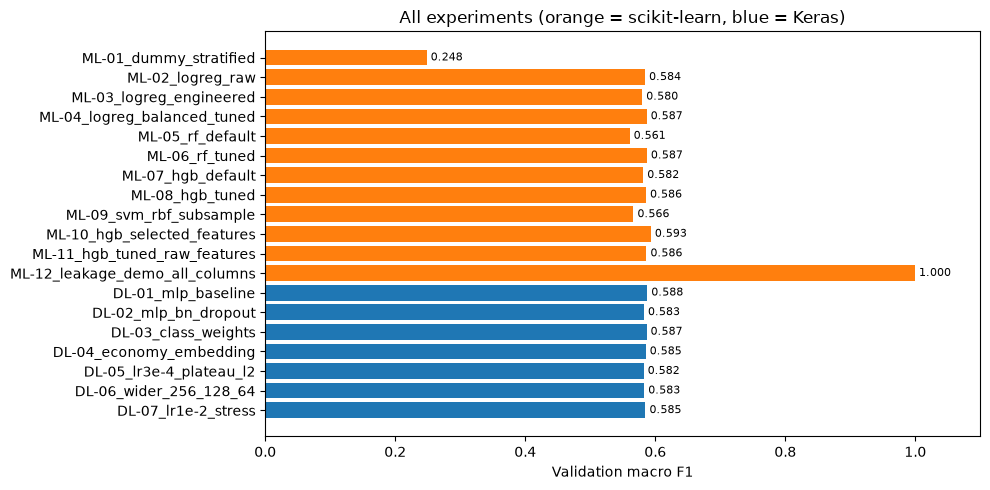

In [21]:
exp = pd.DataFrame(EXPERIMENTS)
show_cols = ["id", "model", "change", "train_macro_f1", "val_macro_f1", "val_balanced_acc", "val_accuracy",
             "val_macro_auc", "gap_macro_f1", "fit_seconds"]
display(exp[show_cols].style.format(precision=4).background_gradient(subset=["val_macro_f1"], cmap="Greens"))

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#ff7f0e" if p == "ML" else "#1f77b4" for p in exp["paradigm"]]
ax.barh(exp["id"][::-1], exp["val_macro_f1"][::-1], color=colors[::-1])
ax.set_xlabel("Validation macro F1")
ax.set_title("All experiments (orange = scikit-learn, blue = Keras)")
ax.set_xlim(0, max(exp["val_macro_f1"]) * 1.1)
for i, v in enumerate(exp["val_macro_f1"][::-1]):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
plt.tight_layout()
save_fig("experiment_comparison")
plt.show()

**What this shows.** Apart from the dummy baseline and the leakage test, every model lands between 0.561 and 0.593 validation macro F1. The best ML model is ML-10 (0.593) and the best DL model is DL-01 (0.588). A band this narrow means the limit comes from the information in the features, not from the algorithm.

## 11. Final test evaluation

The best model of each paradigm is chosen on **validation macro F1**, then evaluated once on the untouched test set. I also bootstrap the test set (1,000 resamples) to get a 95% confidence interval for macro F1, so I can tell whether the ML vs DL difference is bigger than chance.

In [22]:
ml_runs = exp[(exp["paradigm"] == "ML") & (~exp["id"].str.contains("dummy|leakage"))]
dl_runs = exp[exp["paradigm"] == "DL"]
BEST_ML = ml_runs.loc[ml_runs["val_macro_f1"].idxmax(), "id"]
BEST_DL = dl_runs.loc[dl_runs["val_macro_f1"].idxmax(), "id"]
print("Best ML:", BEST_ML, "| Best DL:", BEST_DL)


def predict_test(run_id):
    model = FITTED[run_id]
    if run_id.startswith("ML"):
        cols = selected if "selected" in run_id else X_test.columns
        return model.predict_proba(X_test[cols])
    uses_emb = len(model.inputs) == 2
    ds = make_dataset(Xte_ne if uses_emb else Xte_dl, None, Ete if uses_emb else None, 1024)
    return model.predict(ds, verbose=0)


TEST_PROBA = {"ML": predict_test(BEST_ML), "DL": predict_test(BEST_DL)}
rng = np.random.default_rng(SEED)
y_test_arr = y_test.values
rows = []
for name, proba in TEST_PROBA.items():
    s = scores(y_test_arr, proba)
    pred = proba.argmax(axis=1)
    boots = []
    for _ in range(1000):
        idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
        boots.append(f1_score(y_test_arr[idx], pred[idx], average="macro"))
    rows.append({"paradigm": name, "model": BEST_ML if name == "ML" else BEST_DL, **{k: round(v, 4) for k, v in s.items()},
                 "macro_f1_95ci": f"{np.percentile(boots, 2.5):.3f} to {np.percentile(boots, 97.5):.3f}"})
final_table = pd.DataFrame(rows).set_index("paradigm")
final_table.to_csv(os.path.join(RESULTS_DIR, "final_test_metrics.csv"))
display(final_table)

for name, proba in TEST_PROBA.items():
    print(f"\n{name} ({final_table.loc[name, 'model']}) per-class report on the test set:")
    print(classification_report(y_test_arr, proba.argmax(axis=1), target_names=CLASS_NAMES, digits=3))

Best ML: ML-10_hgb_selected_features | Best DL: DL-01_mlp_baseline


,model,macro_f1,balanced_acc,accuracy,macro_auc,macro_f1_95ci
paradigm,,,,,,
ML,ML-10_hgb_selected_features,0.5967,0.6089,0.6299,0.8475,0.583 to 0.610
DL,DL-01_mlp_baseline,0.5957,0.5889,0.6562,0.8495,0.582 to 0.609



ML (ML-10_hgb_selected_features) per-class report on the test set:
                            precision    recall  f1-score   support

                No account      0.824     0.684     0.748      2471
         Mobile money only      0.428     0.640     0.513       956
Financial institution only      0.517     0.495     0.506       964
                      Both      0.625     0.616     0.621      1019

                  accuracy                          0.630      5410
                 macro avg      0.598     0.609     0.597      5410
              weighted avg      0.662     0.630     0.639      5410


DL (DL-01_mlp_baseline) per-class report on the test set:
                            precision    recall  f1-score   support

                No account      0.742     0.828     0.783      2471
         Mobile money only      0.471     0.483     0.477       956
Financial institution only      0.619     0.411     0.494       964
                      Both      0.625     0.633     0

**What this shows.** On the test set both models reach about 0.60 macro F1 (ML 0.597, DL 0.596) and their bootstrap intervals overlap almost completely, so neither is genuinely better. They make different trade-offs: the class-weighted gradient boosting model has higher balanced accuracy (0.609), while the unweighted network has higher accuracy (0.656) because it predicts "No account" more often. Validation and test scores agree (0.593 vs 0.597 for ML), so the model was not over-tuned to the validation set.

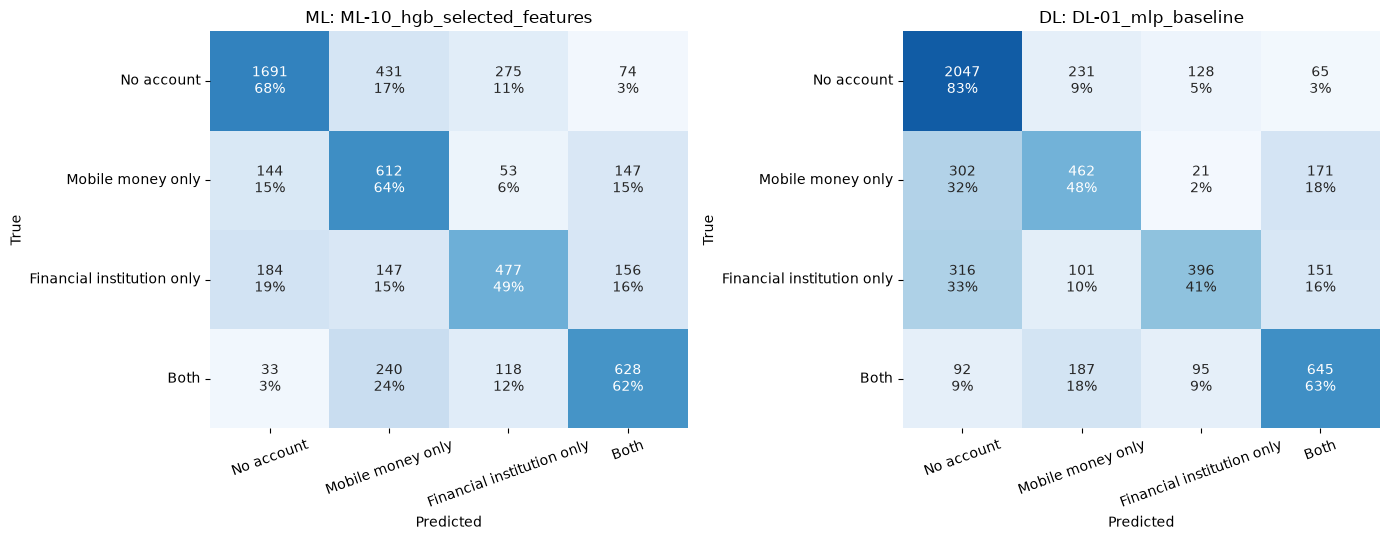

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, proba) in zip(axes, TEST_PROBA.items()):
    cm = confusion_matrix(y_test_arr, proba.argmax(axis=1))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i, j]}\n{cm_norm[i, j]:.0%}" for j in range(N_CLASSES)] for i in range(N_CLASSES)])
    sns.heatmap(cm_norm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, vmax=1)
    ax.set_title(f"{name}: {final_table.loc[name, 'model']}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
save_fig("confusion_matrices_test")
plt.show()

**What this shows.** "No account" is the easiest class (recall 0.684 for ML, 0.828 for DL) and "Financial institution only" the hardest (0.495 and 0.411). The most common ML mistake is calling people with no account "Mobile money only" (431 cases). The network, trained without class weights, errs the other way and labels about a third of mobile-only and bank-only users as having no account.

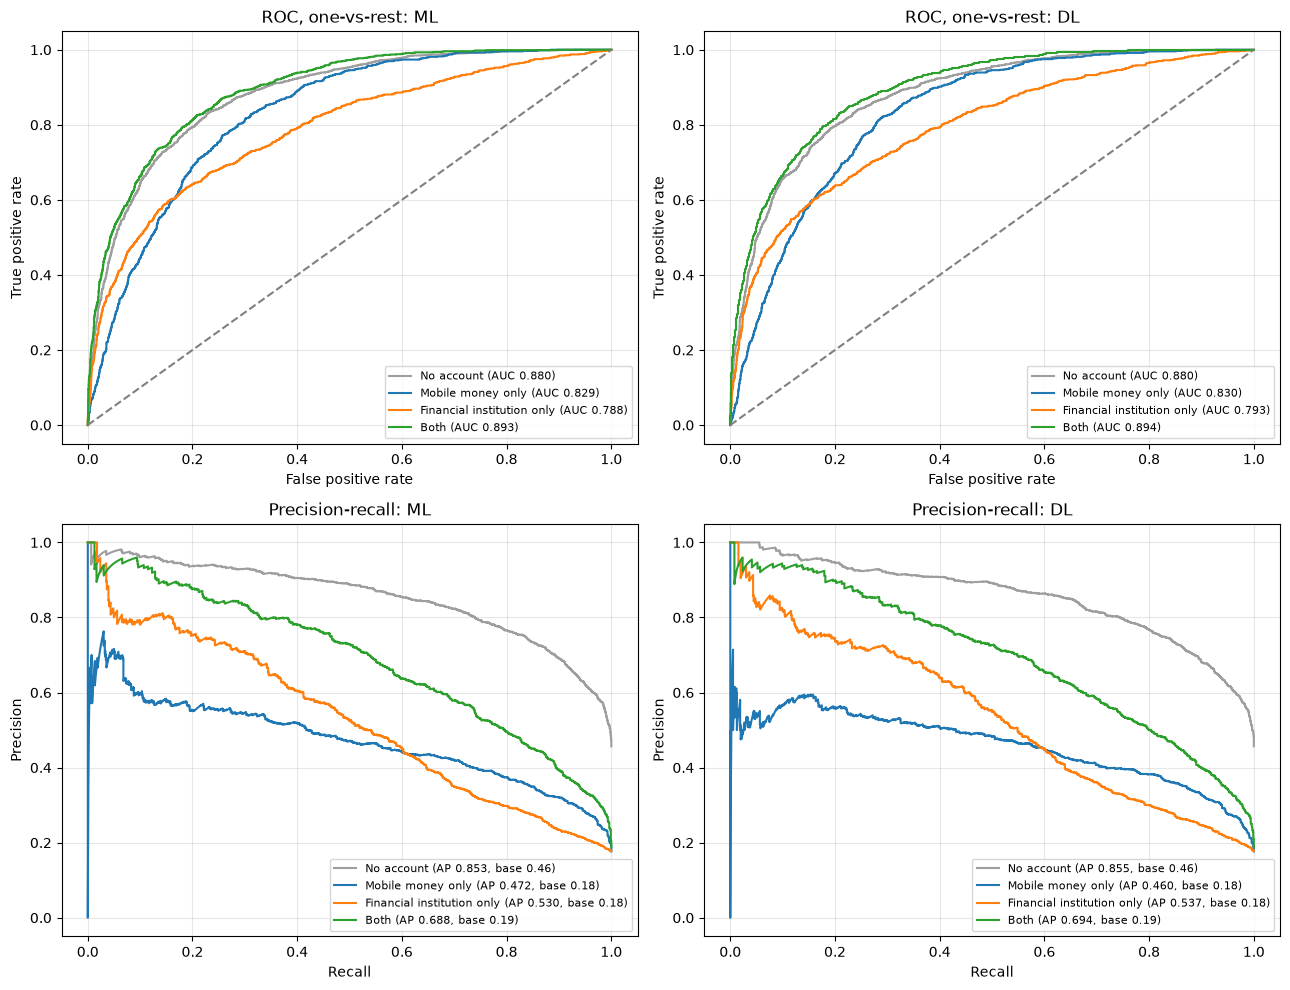

In [24]:
y_bin = label_binarize(y_test_arr, classes=np.arange(N_CLASSES))
colors = ["#9e9e9e", "#1f77b4", "#ff7f0e", "#2ca02c"]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for col, (name, proba) in enumerate(TEST_PROBA.items()):
    ax_roc, ax_pr = axes[0, col], axes[1, col]
    for k in range(N_CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, k], proba[:, k])
        ax_roc.plot(fpr, tpr, color=colors[k], label=f"{CLASS_NAMES[k]} (AUC {roc_auc_score(y_bin[:, k], proba[:, k]):.3f})")
        prec, rec, _ = precision_recall_curve(y_bin[:, k], proba[:, k])
        ax_pr.plot(rec, prec, color=colors[k],
                   label=f"{CLASS_NAMES[k]} (AP {average_precision_score(y_bin[:, k], proba[:, k]):.3f}, base {y_bin[:, k].mean():.2f})")
    ax_roc.plot([0, 1], [0, 1], "--", color="grey")
    ax_roc.set_title(f"ROC, one-vs-rest: {name}")
    ax_roc.set_xlabel("False positive rate")
    ax_roc.set_ylabel("True positive rate")
    ax_pr.set_title(f"Precision-recall: {name}")
    ax_pr.set_xlabel("Recall")
    ax_pr.set_ylabel("Precision")
    for ax in (ax_roc, ax_pr):
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
plt.tight_layout()
save_fig("roc_pr_test")
plt.show()

**What this shows.** Every class has a one-vs-rest AUC between 0.79 (bank only) and 0.89 (both), so the models rank people well even when the hard prediction is wrong. Precision-recall is harsher on the small classes: average precision is 0.47 for "Mobile money only" against 0.85 for "No account", though still far above the 0.18 base rate.

## 12. Learning curves and bias-variance

- **ML learning curve**: the best ML model retrained on growing fractions of the training set (3-fold CV each). If train and CV scores are far apart and the CV curve is still rising, more data would help (variance). If both are low and flat, the model is too simple (bias).
- **Validation curve**: one complexity knob of the best ML model, swept from simple to complex, shows the bias-variance trade-off directly.
- **DL learning curves**: training vs validation loss and accuracy per epoch for the best network.

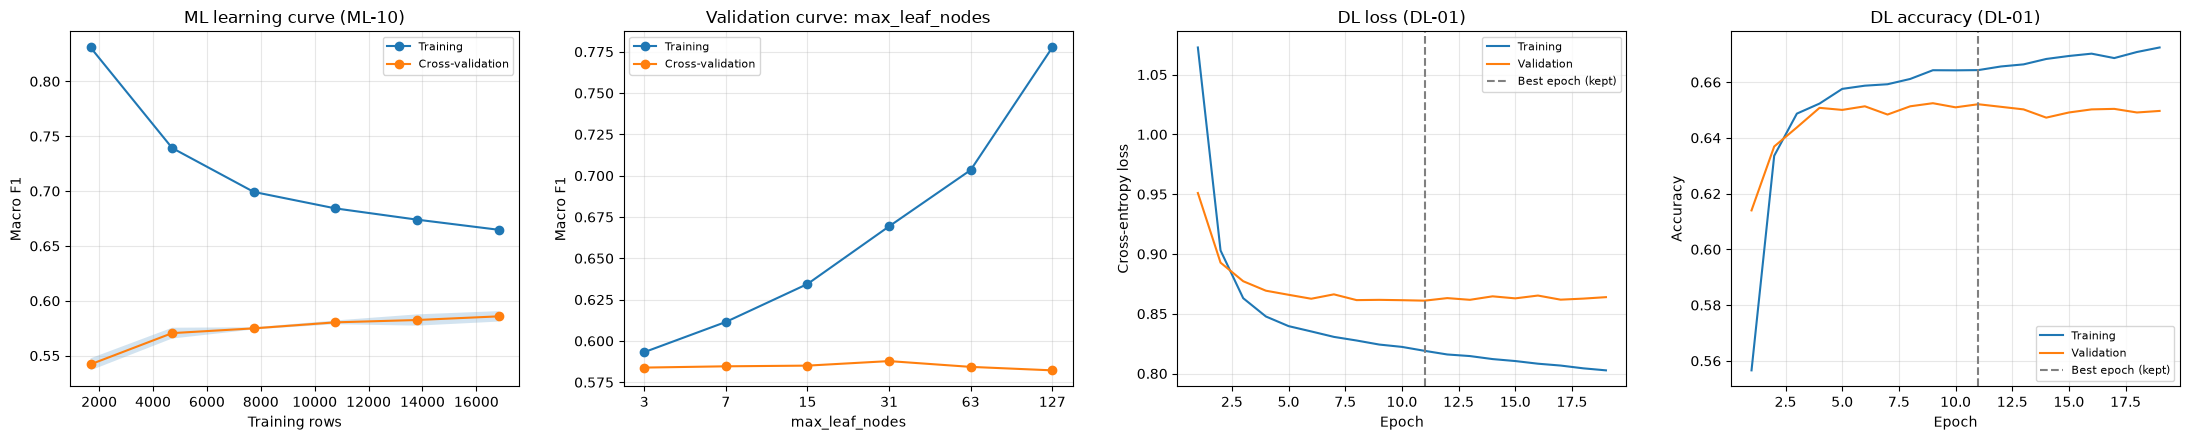

ML learning curve (train rows, train F1, CV F1):
    1682: 0.831  0.542
    4711: 0.739  0.571
    7740: 0.699  0.575
   10769: 0.684  0.580
   13798: 0.674  0.582
   16828: 0.665  0.586
Validation curve over max_leaf_nodes: {3: (np.float64(0.593), np.float64(0.584)), 7: (np.float64(0.611), np.float64(0.585)), 15: (np.float64(0.634), np.float64(0.585)), 31: (np.float64(0.669), np.float64(0.588)), 63: (np.float64(0.703), np.float64(0.584)), 127: (np.float64(0.778), np.float64(0.582))}


In [25]:
best_ml_pipe = FITTED[BEST_ML]
ml_cols = selected if "selected" in BEST_ML else X_train.columns
sizes, tr_scores, cv_scores = learning_curve(best_ml_pipe, X_train[ml_cols], y_train, cv=CV, scoring="f1_macro",
                                             train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, shuffle=True,
                                             random_state=SEED)

model_step = best_ml_pipe.named_steps["model"]
if isinstance(model_step, HistGradientBoostingClassifier):
    knob, knob_values, knob_label = "model__max_leaf_nodes", [3, 7, 15, 31, 63, 127], "max_leaf_nodes"
elif isinstance(model_step, RandomForestClassifier):
    knob, knob_values, knob_label = "model__max_depth", [2, 4, 8, 12, 16, 24], "max_depth"
else:
    knob, knob_values, knob_label = "model__C", [0.001, 0.01, 0.1, 1, 10], "C"
vc_tr, vc_cv = validation_curve(best_ml_pipe, X_train[ml_cols], y_train, param_name=knob, param_range=knob_values,
                                cv=CV, scoring="f1_macro", n_jobs=-1)

h = DL_HISTORY[BEST_DL]
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
axes[0].plot(sizes, tr_scores.mean(axis=1), "o-", label="Training")
axes[0].plot(sizes, cv_scores.mean(axis=1), "o-", label="Cross-validation")
axes[0].fill_between(sizes, cv_scores.mean(axis=1) - cv_scores.std(axis=1), cv_scores.mean(axis=1) + cv_scores.std(axis=1), alpha=0.2)
axes[0].set_title(f"ML learning curve ({BEST_ML.split('_')[0]})")
axes[0].set_xlabel("Training rows")
axes[0].set_ylabel("Macro F1")

axes[1].plot([str(v) for v in knob_values], vc_tr.mean(axis=1), "o-", label="Training")
axes[1].plot([str(v) for v in knob_values], vc_cv.mean(axis=1), "o-", label="Cross-validation")
axes[1].set_title(f"Validation curve: {knob_label}")
axes[1].set_xlabel(knob_label)
axes[1].set_ylabel("Macro F1")

epochs = range(1, len(h["loss"]) + 1)
best_epoch = int(np.argmin(h["val_loss"])) + 1
axes[2].plot(epochs, h["loss"], label="Training")
axes[2].plot(epochs, h["val_loss"], label="Validation")
axes[2].set_title(f"DL loss ({BEST_DL.split('_')[0]})")
axes[2].set_ylabel("Cross-entropy loss")
axes[3].plot(epochs, h["accuracy"], label="Training")
axes[3].plot(epochs, h["val_accuracy"], label="Validation")
axes[3].set_title(f"DL accuracy ({BEST_DL.split('_')[0]})")
axes[3].set_ylabel("Accuracy")
for ax in axes[2:]:
    ax.axvline(best_epoch, color="grey", linestyle="--", label="Best epoch (kept)")
    ax.set_xlabel("Epoch")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
save_fig("learning_curves")
plt.show()

print("ML learning curve (train rows, train F1, CV F1):")
for s, a, b in zip(sizes, tr_scores.mean(axis=1), cv_scores.mean(axis=1)):
    print(f"  {s:>6}: {a:.3f}  {b:.3f}")
print(f"Validation curve over {knob_label}:", {v: (round(a, 3), round(b, 3)) for v, a, b in zip(knob_values, vc_tr.mean(axis=1), vc_cv.mean(axis=1))})

**What this shows.** As the training set grows, training F1 falls from 0.831 to 0.665 while cross-validated F1 rises from 0.542 to 0.586 and nearly flattens, so more of the same data would help only a little: the model is limited by bias, not variance. The validation curve shows the trade-off directly. More leaves keep raising training F1 (0.593 to 0.778), but cross-validated F1 peaks at 31 leaves (0.588) and then falls. For the network, validation loss bottoms out at epoch 11 while training loss keeps dropping, and that is the epoch early stopping kept.

## 13. Error analysis

Three angles:

1. **Which classes get confused** (from the confusion matrices above) and what the confused people look like.
2. **Who the model works worse for**: recall of the "No account" class (the people we most want to find) by gender, rural/urban and income quintile, and accuracy per economy compared with guessing each country's most common class.
3. **What drives predictions**: permutation importance (section 8) and the coefficients of the interpretable logistic regression (ML-04), compared side by side.

In [26]:
best_proba = TEST_PROBA["ML"] if final_table.loc["ML", "macro_f1"] >= final_table.loc["DL", "macro_f1"] else TEST_PROBA["DL"]
best_name = "ML" if best_proba is TEST_PROBA["ML"] else "DL"
test_view = X_test.copy()
test_view["true"] = [CLASS_NAMES[i] for i in y_test_arr]
test_view["pred"] = [CLASS_NAMES[i] for i in best_proba.argmax(axis=1)]
test_view["correct"] = test_view["true"] == test_view["pred"]

confusions = (test_view[~test_view["correct"]].groupby(["true", "pred"]).size()
              .sort_values(ascending=False).rename("count").reset_index())
print(f"Most common mistakes of the overall best model ({best_name}):")
display(confusions.head(6))

profile_cols = ["age", "educ", "inc_q", "mobileowner", "internetaccess", "fin32", "saved"]
top_pair = confusions.iloc[0]
pair = test_view[(test_view["true"] == top_pair["true"]) & (test_view["pred"].isin([top_pair["true"], top_pair["pred"]]))]
print(f"\nProfile of true '{top_pair['true']}': predicted correctly vs predicted as '{top_pair['pred']}'")
display(pair.groupby("pred")[profile_cols].mean().round(2))

Most common mistakes of the overall best model (ML):


,true,pred,count
0,No account,Mobile money only,431
1,No account,Financial institution only,275
2,Both,Mobile money only,240
3,Financial institution only,No account,184
4,Financial institution only,Both,156
5,Financial institution only,Mobile money only,147



Profile of true 'No account': predicted correctly vs predicted as 'Mobile money only'


,age,educ,inc_q,mobileowner,internetaccess,fin32,saved
pred,,,,,,,
Mobile money only,32.55,1.59,3.14,0.92,0.37,0.15,0.63
No account,32.80,1.25,2.73,0.46,0.13,0.06,0.19


**What this shows.** The people with no account whom the model calls "Mobile money only" are not random mistakes: 92% own a phone (vs 46%), 37% have internet (vs 13%) and 63% saved in the past year (vs 19%). They look like mobile money users in every way the survey measures, so for a digital finance programme they are a natural first target.

,group,rows,recall_no_account
0,female = female,1489,0.714
1,female = male,982,0.640
2,urbanicity = not asked (phone survey),37,0.135
3,urbanicity = rural,1451,0.735
4,urbanicity = urban,983,0.630
5,inc_q = 1,579,0.775
6,inc_q = 2,501,0.695
7,inc_q = 3,489,0.710
8,inc_q = 4,480,0.627
9,inc_q = 5,422,0.583


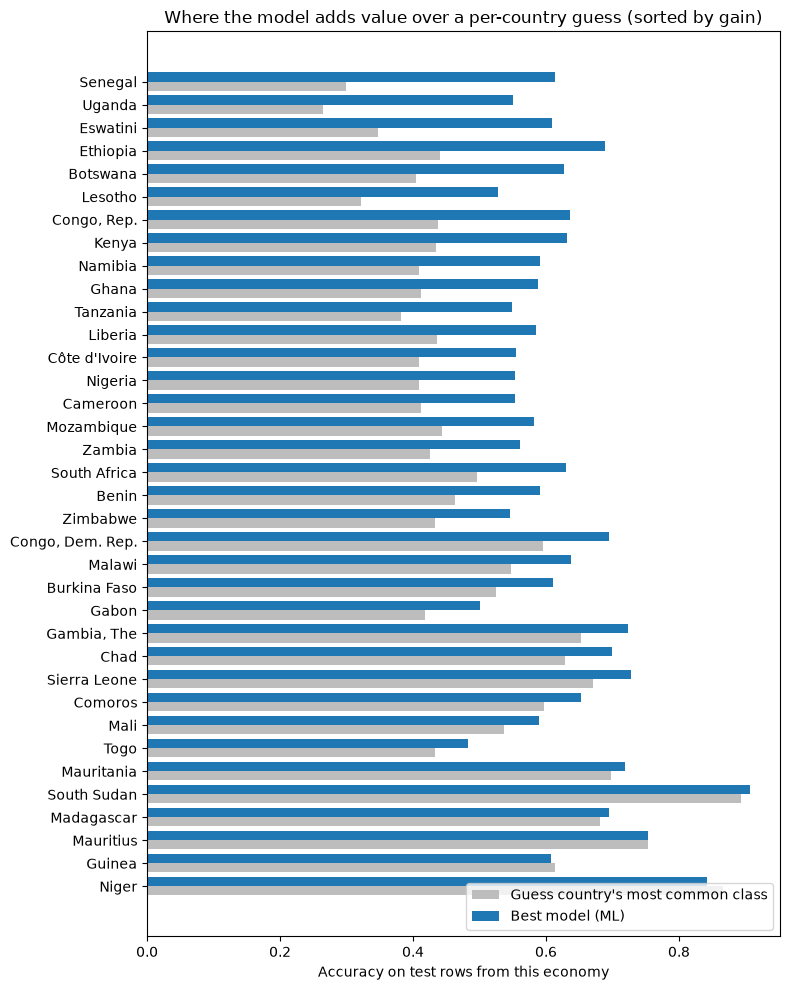

Largest gains: {'Botswana': 0.222, 'Ethiopia': 0.248, 'Eswatini': 0.261, 'Uganda': 0.286, 'Senegal': 0.314}
Smallest gains: {'Niger': -0.024, 'Guinea': -0.006, 'Mauritius': 0.0, 'Madagascar': 0.013, 'South Sudan': 0.013}
Model beats the per-country guess in 33 of 36 economies


In [27]:
no_acc = test_view[test_view["true"] == "No account"]
group_recall = []
for col, mapping in [("female", {1.0: "female", 0.0: "male"}), ("urbanicity", None), ("inc_q", None)]:
    keys = no_acc[col].map(mapping) if mapping else no_acc[col]
    for g, part in no_acc.groupby(keys):
        group_recall.append({"group": f"{col} = {g}", "rows": len(part),
                             "recall_no_account": round((part["pred"] == "No account").mean(), 3)})
display(pd.DataFrame(group_recall))

# Macro F1 inside one country is pulled down by classes that are rare there, so per country I compare
# accuracy against the simplest alternative: always guessing that country's most common class.
train_majority = pd.DataFrame({"economy": X_train["economy"], "y": y_train}).groupby("economy")["y"].agg(lambda s: s.mode()[0])
per_country = []
for econ, g in test_view.assign(t=y_test_arr, p=best_proba.argmax(axis=1)).groupby("economy"):
    per_country.append({"economy": econ, "rows": len(g), "model_accuracy": (g["t"] == g["p"]).mean(),
                        "majority_baseline": (g["t"] == train_majority[econ]).mean()})
per_country = pd.DataFrame(per_country).set_index("economy")
per_country["gain"] = per_country["model_accuracy"] - per_country["majority_baseline"]
per_country = per_country.sort_values("gain")

fig, ax = plt.subplots(figsize=(8, 10))
y_pos = np.arange(len(per_country))
ax.barh(y_pos - 0.2, per_country["majority_baseline"], height=0.4, color="#bdbdbd", label="Guess country's most common class")
ax.barh(y_pos + 0.2, per_country["model_accuracy"], height=0.4, color="#1f77b4", label=f"Best model ({best_name})")
ax.set_yticks(y_pos)
ax.set_yticklabels(per_country.index)
ax.set_xlabel("Accuracy on test rows from this economy")
ax.set_title("Where the model adds value over a per-country guess (sorted by gain)")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("accuracy_by_economy")
plt.show()
print("Largest gains:", per_country["gain"].tail(5).round(3).to_dict())
print("Smallest gains:", per_country["gain"].head(5).round(3).to_dict())
print(f"Model beats the per-country guess in {(per_country['gain'] > 0).sum()} of {len(per_country)} economies")
per_country.round(3).to_csv(os.path.join(RESULTS_DIR, "accuracy_by_economy.csv"))

**What this shows.** The model finds excluded women (recall 0.714), rural adults (0.735) and the poorest quintile (0.775) better than excluded men (0.640), urban adults (0.630) or the richest quintile (0.583). This is mostly because exclusion is more common in the first group of each pair, but it means excluded urban or richer adults are more likely to be missed. By country, the model beats a "most common class" guess in 33 of 36 economies, most clearly in Senegal (+31 points) and Uganda (+29), but not in Niger and Guinea, where one class dominates.

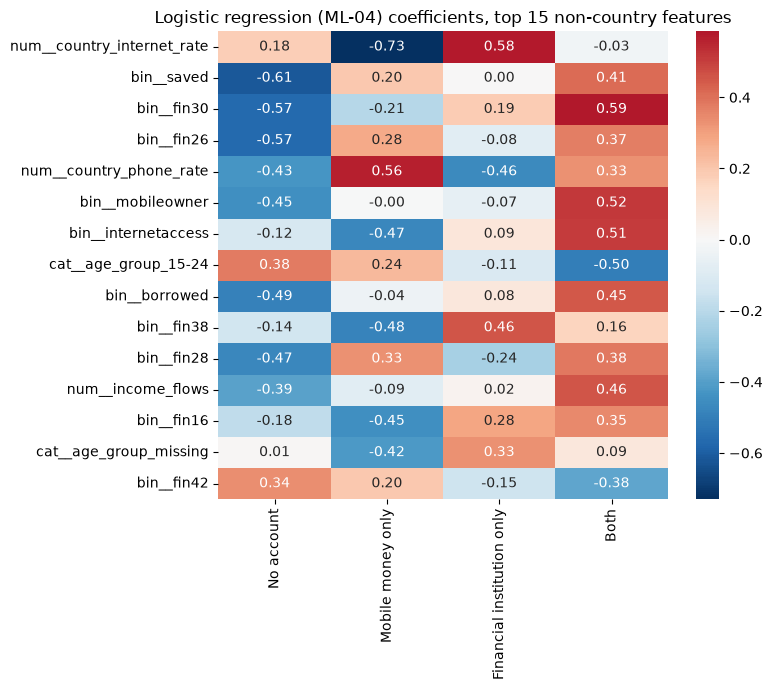

In [28]:
logreg = FITTED["ML-04_logreg_balanced_tuned"]
feature_names = logreg.named_steps["prep"].named_steps["columns"].get_feature_names_out()
coefs = pd.DataFrame(logreg.named_steps["model"].coef_.T, index=feature_names, columns=CLASS_NAMES)
coefs = coefs[~coefs.index.str.startswith("cat__economy")]
top_features = coefs.abs().max(axis=1).sort_values(ascending=False).head(15).index
plt.figure(figsize=(8, 7))
sns.heatmap(coefs.loc[top_features], annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Logistic regression (ML-04) coefficients, top 15 non-country features")
plt.tight_layout()
save_fig("logreg_coefficients")
plt.show()

**What this shows.** The coefficients make the model's logic readable. Saving (-0.61), paying a utility bill (-0.57) and sending remittances (-0.57) all push away from "No account". Receiving a pension (+0.46) points to a bank-only account, which fits pensions usually being paid into banks. The country features separate the two channels: a higher share of phone owners in the country favours "Mobile money only" (+0.56), while a higher share of internet users favours "Financial institution only" (+0.58) and works against mobile-only (-0.73). Young adults aged 15 to 24 lean towards "No account" (+0.38) and away from "Both" (-0.50).

## 14. Generalisation to unseen countries

The random split puts people from the same country in both training and test. A product team, though, might want to use this model in a country that was not surveyed. To estimate that, I retrain the best ML configuration with **grouped 5-fold cross-validation by economy**: each fold holds out whole countries. A large drop compared with the random split means the model leans on country-specific patterns.

In [29]:
X_all = pd.concat([X_train, X_val])[ml_cols]
y_all = pd.concat([y_train, y_val])
groups = pd.concat([X_train, X_val])["economy"]
fold_scores = []
for fold, (tr_idx, te_idx) in enumerate(GroupKFold(n_splits=5).split(X_all, y_all, groups)):
    model = sklearn.base.clone(best_ml_pipe).fit(X_all.iloc[tr_idx], y_all.iloc[tr_idx])
    proba = model.predict_proba(X_all.iloc[te_idx])
    s = scores(y_all.iloc[te_idx], proba)
    fold_scores.append({"fold": fold + 1, "held_out_economies": groups.iloc[te_idx].nunique(), **{k: round(v, 4) for k, v in s.items()}})
lco = pd.DataFrame(fold_scores)
display(lco)
print(f"Leave-countries-out macro F1: {lco['macro_f1'].mean():.3f} +/- {lco['macro_f1'].std():.3f} "
      f"vs {final_table.loc['ML', 'macro_f1']:.3f} on the random test split")
lco.to_csv(os.path.join(RESULTS_DIR, "leave_country_out.csv"), index=False)

,fold,held_out_economies,macro_f1,balanced_acc,accuracy,macro_auc
0,1,7,0.4574,0.4636,0.5416,0.7527
1,2,8,0.5104,0.5247,0.5240,0.7891
2,3,7,0.4852,0.5014,0.5564,0.7900
3,4,7,0.5112,0.5266,0.6297,0.8156
4,5,7,0.4482,0.4600,0.4930,0.7516


Leave-countries-out macro F1: 0.482 +/- 0.029 vs 0.597 on the random test split


**What this shows.** Holding out whole countries drops macro F1 from 0.597 to 0.482 ± 0.029 (AUC 0.75 to 0.82). The model leans heavily on country-specific patterns, so it should not be used in a new country such as Rwanda without some local training data.

## 15. Saving the best models

- Best traditional ML model: the whole scikit-learn pipeline (feature engineering + preprocessing + model) as `.joblib`, so it can be loaded and used on raw cleaned survey rows directly.
- Best deep learning model: Keras native `.keras` file and an `.h5` copy, plus the fitted preprocessing pipeline it needs.

These files go in the Google Drive folder (they are not committed to GitHub).

In [30]:
joblib.dump(FITTED[BEST_ML], os.path.join(MODEL_DIR, "best_ml_model.joblib"))
best_dl = FITTED[BEST_DL]
best_dl.save(os.path.join(MODEL_DIR, "best_dl_model.keras"))
best_dl.save(os.path.join(MODEL_DIR, "best_dl_model.h5"))
uses_emb = len(best_dl.inputs) == 2
joblib.dump({"preprocessor": dl_prep_noecon if uses_emb else dl_prep, "economy_index": ECON_INDEX,
             "uses_economy_embedding": uses_emb, "class_names": CLASS_NAMES},
            os.path.join(MODEL_DIR, "best_dl_preprocessing.joblib"))

reloaded = joblib.load(os.path.join(MODEL_DIR, "best_ml_model.joblib"))
check = np.allclose(reloaded.predict_proba(X_test[ml_cols]), TEST_PROBA["ML"])
print("Saved:", sorted(os.listdir(MODEL_DIR)), "| ML reload matches:", check)

Saved: ['README.md', 'best_dl_model.h5', 'best_dl_model.keras', 'best_dl_preprocessing.joblib', 'best_ml_model.joblib'] | ML reload matches: True


**What this shows.** The saved pipeline reloads and gives exactly the same predictions, so the model files in the Google Drive folder reproduce the reported results.

### Viewing the TensorBoard logs

Every row of the experiment table has a matching run in `logs/fit/`. In Colab or Jupyter:

```
%load_ext tensorboard
%tensorboard --logdir logs/fit
```

The **HParams** tab lists every run with its settings and validation metrics; the **Scalars** tab shows the per-epoch curves of the deep learning runs.